# 2. Was the comparison planned and allocated sensibly?

This notebook reads the documented plan, reproduces its sample-size calculations and checks allocation and baseline balance.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'config').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from support_policy.common import config
mart = pl.read_parquet(ROOT / 'data/marts/experiment_mart.parquet')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pl.Config.set_tbl_rows(20)
print(f'{mart.height:,} customers; synthetic data only')


100,000 customers; synthetic data only


## Decision thresholds
These are illustrative business choices fixed for this exercise, not Uber targets. Changing them after seeing results would weaken the decision process.

In [2]:
display(config('analysis_plan'))

{'version': 1,
 'assignment_unit': 'customer',
 'allocation_probability': 0.5,
 'followup_hours': 168,
 'primary_metric': 'unresolved_hours_7d',
 'primary_required_reduction_hours': 2.0,
 'alpha': 0.05,
 'power': 0.8,
 'planning_primary_sd_hours': 35.0,
 'planning_repeat_baseline': 0.12,
 'guardrail_limits': {'repeat_contact_7d': 0.01,
  'escalated_7d': 0.005,
  'refund_usd_7d': 0.5},
 'segments': ['issue_type', 'region', 'tenure_group']}

## Sample-size planning
The primary calculation tests a 2-hour change against zero. Proving at least a 2-hour improvement is a stronger requirement and needs additional power planning.

In [3]:
from support_policy.power_analysis import calculate_power
power=calculate_power()
display(power)


{'primary_n_per_arm': 4809,
 'repeat_guardrail_n_per_arm_approx': 18626,
 'planned_total': 100000,
 'note': 'Primary power detects a 2-hour difference from zero; it does not give 80% power to prove at least a 2-hour reduction. Guardrail planning assumes a true zero effect. No joint power guarantee; escalation and cost need separate planning in production.'}

## Allocation check
Independent 50/50 randomisation does not require exactly equal arm sizes. The sample-ratio mismatch test flags an unexpected imbalance, not treatment success.

In [4]:
from support_policy.experiment_checks import check_experiment
health=check_experiment(mart)
display(health)
assert health['unique_customer_grain'] and health['complete_followup']


{'n_control': 50180,
 'n_treatment': 49820,
 'srm_p_value': 0.25494516431731784,
 'srm_pass': True,
 'max_absolute_smd': 0.00752583731620379,
 'unique_customer_grain': True,
 'complete_followup': True,
 'note': 'SRM flags p<0.001. SMD is descriptive; |SMD|>0.1 prompts investigation, not outcome-based exclusions.'}

## Baseline balance
Standardised differences describe comparability. They are not used to drop customers or search for favourable subgroups.

feature,control,treatment,smd
str,f64,f64,f64
"""tenure_days""",750.630411,749.255098,-0.003178
"""prior_contacts_30d""",0.696991,0.703292,0.007526
"""region: Region A""",0.499482,0.499458,-0.000048
"""region: Region B""",0.301813,0.303171,0.002956
"""region: Region C""",0.198705,0.197371,-0.003348
"""issue_type: Cancellation refun…",0.250976,0.248434,-0.005873
"""issue_type: Duplicate charge""",0.300399,0.299739,-0.001439
"""issue_type: Fare adjustment""",0.448625,0.451827,0.006435
"""tenure_group: 6 months or more""",0.880909,0.879105,-0.005551


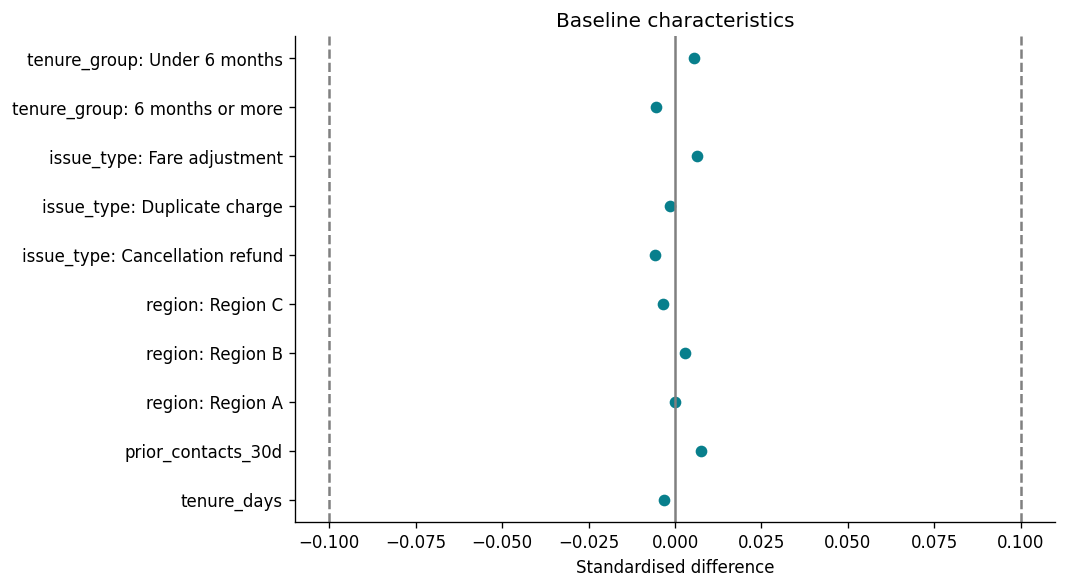

In [5]:
balance=pl.read_csv(ROOT/'outputs/tables/baseline_balance.csv')
display(balance)
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter(balance['smd'].to_list(),balance['feature'].to_list(),color='#087f8c')
ax.axvline(0,color='grey');ax.axvline(.1,ls='--',color='grey');ax.axvline(-.1,ls='--',color='grey')
ax.set(xlabel='Standardised difference',title='Baseline characteristics');plt.tight_layout();plt.show()


## Follow-up maturity
The inclusion rule depends on assignment time and the data cutoff, never on whether a case resolved.

In [6]:
from datetime import datetime
end=datetime.fromisoformat(config('simulation')['observation_end'])
print('Observation cutoff:',end,'UTC')
print('Latest window end:',mart['window_end'].max())
assert mart['window_end'].max()<=end
assert ((mart['window_end']-mart['assigned_at']).dt.total_hours()==168).all()


Observation cutoff: 2026-04-08 00:00:00 UTC
Latest window end: 2026-04-04 23:59:47


## Interpretation
Passing these checks supports the mechanics of the comparison. It does not prove that logging is perfect in a real system, or remove spillover and nonresponse risks. Those are assumptions to investigate before a live launch.